# 🏭 Hệ Thống Phát Hiện & Phân Loại Lỗi Băng Tải 2 Giai Đoạn (Two-Stage Inspection Pipeline)

Notebook này triển khai giải pháp học sâu 2 giai đoạn kết hợp **Anomaly Detection** và **Fine-tuned Defect Classification** giải quyết triệt để vấn đề lỗi vi mô trên bề mặt sản phẩm công nghiệp:

---

### 📌 Luồng Hoạt Động (Architecture Flow)
```
                     [ 📸 Ảnh Toàn Phần Đầu Vào (Full Image) ]
                                         │
                                         ▼
     ┌────────────────────────────────────────────────────────────────────────┐
     │ Giai đoạn 1: ResNet-50 + PatchCore (Phát hiện Bất thường Toàn phần)    │
     │ • Mạng lớn ResNet-50 trích xuất đặc trưng đa tầng (layer2 + layer3)    │
     │ • Memory Bank xây dựng HOÀN TOÀN từ Dữ liệu Lành (nhãn 1: chip)        │
     │ • Greedy Coreset Subsampling nén bộ nhớ cho tốc độ suy luận cao        │
     └───────────────────────────────────┬────────────────────────────────────┘
                                         │
                          [ So sánh Anomaly Score & Ngưỡng tau ]
                         /                                      \
                Score <= tau                                    Score > tau
                       /                                          \
                      ▼                                            ▼
       ┌─────────────────────────┐               ┌───────────────────────────────────────────────┐
       │ ✅ VẬT LÀNH (NORMAL)     │               │ 🔴 VẬT LỖI (DEFECT DETECTED)                  │
       │ Bề mặt đạt chuẩn        │               │ Bắt đầu chu trình tự định vị khuyết tật       │
       └─────────────────────────┘               └───────────────────────┬───────────────────────┘
                                                                         │
                                                                         ▼
                                                 ┌───────────────────────────────────────────────┐
                                                 │ 🔍 TỰ ĐỊNH VỊ & CẮT VUÔNG LỖI (AUTONOMOUS CROP)│
                                                 │ • Không dùng file nhãn khi kiểm thử/suy luận  │
                                                 │ • Tự tìm vùng dị thường từ PatchCore Heatmap  │
                                                 │ • Cắt khung hình vuông quanh tâm bất thường   │
                                                 │ • Loại bỏ 95% diện tích nền trắng áp đảo      │
                                                 └───────────────────────┬───────────────────────┘
                                                                         │
                                                                         ▼
                                                 ┌───────────────────────────────────────────────┐
                                                 │ Giai đoạn 2: ResNet-18 (Unfreeze layer4 + Head│
                                                 │ • Đóng băng conv1, layer1, layer2, layer3     │
                                                 │ • Mở khóa layer4 (lr=1e-4) & FC Head (lr=1e-3)│
                                                 │ • Huấn luyện 20 Epochs trên ảnh cắt lỗi       │
                                                 │   (2: crack, 3: glaze, 4: pin_hole, 5: scratch│
                                                 └───────────────────────┬───────────────────────┘
                                                                         │
                                                                         ▼
                                                 ┌───────────────────────────────────────────────┐
                                                 │ 📊 KẾT QUẢ CHẨN ĐOÁN & TỶ LỆ XÁC SUẤT (%)     │
                                                 │ • crack (nhãn 2)   :  xx.xx%                  │
                                                 │ • glaze (nhãn 3)   :  xx.xx%                  │
                                                 │ • pin_hole (nhãn 4):  xx.xx%                  │
                                                 │ • scratch (nhãn 5) :  xx.xx%                  │
                                                 │ + Bounding Box tự vẽ & PatchCore Heatmap      │
                                                 └───────────────────────────────────────────────┘
```

---

### 🏷️ Quy Ước Nhãn & Xử Lý Dữ Liệu
- **Nhãn 1 (`chip`)**: Được quy ước là **Vật Lành / Không Lỗi** $
ightarrow$ Dùng huấn luyện Memory Bank cho **ResNet-50 PatchCore**.
- **Nhãn 2 (`crack`)**: Vết nứt bề mặt.
- **Nhãn 3 (`glaze`)**: Khuyết tật men.
- **Nhãn 4 (`pin_hole`)**: Lỗ châm kim.
- **Nhãn 5 (`scratch`)**: Vết trầy xước.
- **Lúc Train**: Cắt đúng khung hình vuông chứa lỗi dựa trên tọa độ polygon trong file nhãn:
  $$x_{\min} = \min(x_1, \dots, x_n), \quad x_{\max} = \max(x_1, \dots, x_n)$$
  $$y_{\min} = \min(y_1, \dots, y_n), \quad y_{\max} = \max(y_1, \dots, y_n)$$
- **Lúc Test / Inference**: Tự động phát hiện và định vị lỗi hoàn toàn bằng bản đồ nhiệt dị thường (PatchCore Anomaly Heatmap), **tuyệt đối không đọc file nhãn labels** để khoanh vùng.

In [1]:
import os
import sys
import random
import time
from pathlib import Path
from collections import Counter

# Đảm bảo hiển thị tiếng Việt UTF-8 chuẩn trên mọi môi trường
if hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    resnet50, ResNet50_Weights,
    resnet18, ResNet18_Weights
)

# Cố định random seed để kết quả có thể tái lập
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(42)

# Thiết bị tính toán (GPU nếu có)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f" Thiết bị tính toán đang dùng: {device}")
if device.type == "cuda":
    print(f" Tên GPU: {torch.cuda.get_device_name(0)}")

 Thiết bị tính toán đang dùng: cuda
 Tên GPU: NVIDIA GeForce RTX 3060 Laptop GPU


## 1. Trích Xuất Tọa Độ Polygon & Tạo Mẫu Cắt Vuông Cho Tập Train
- Đọc chuỗi tọa độ $(x_i, y_i)$ trong file nhãn của tập train/val:
  $$x_{\min} = \min(x_1, \dots, x_n), \quad x_{\max} = \max(x_1, \dots, x_n)$$
  $$y_{\min} = \min(y_1, \dots, y_n), \quad y_{\max} = \max(y_1, \dots, y_n)$$
- Tạo khung **hình vuông** bao bọc lỗi kèm khoảng đệm padding để lưu giữ chi tiết vi mô cho ResNet-18 lúc train:
  $$\text{side} = \max(bw, bh) \times (1 + \text{padding\_ratio})$$
- Phân tách riêng:
  - Danh sách ảnh **Vật Lành (nhãn 1)** để fit PatchCore ResNet-50.
  - Danh sách các **vùng cắt lỗi (nhãn 2-5)** để train ResNet-18.

In [2]:
NORMAL_LABEL = 1
DEFECT_CLASSES = {
    2: "crack",
    3: "glaze",
    4: "pin_hole",
    5: "scratch"
}
LABEL_TO_IDX = {2: 0, 3: 1, 4: 2, 5: 3}
IDX_TO_LABEL = {v: k for k, v in LABEL_TO_IDX.items()}
CLASS_NAMES = ["crack", "glaze", "pin_hole", "scratch"]

# Tìm thư mục data
cwd = Path.cwd().resolve()
data_candidates = [cwd / "data", cwd.parent / "data"]
DATA_DIR = next((p for p in data_candidates if p.is_dir()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Không tìm thấy thư mục 'data'. Hãy kiểm tra lại vị trí thực thi.")

def parse_label_boxes(lbl_path, img_w, img_h, padding_ratio=0.20, min_size=32):
    """
    Đọc file nhãn YOLO (cả dạng BBox 5 số và dạng Polygon chuỗi x1 y1 x2 y2 ...),
    áp dụng công thức xmin, xmax, ymin, ymax và khoanh thành khung hình vuông.
    Trả về danh sách: [(class_id, square_crop_box, raw_box)]
    """
    if not lbl_path.exists():
        return []
    lines = [l.strip() for l in lbl_path.read_text().splitlines() if l.strip()]
    boxes = []
    for line in lines:
        parts = [float(v) for v in line.split()]
        if not parts:
            continue
        cls_id = int(parts[0])
        coords = parts[1:]
        if len(coords) >= 4:
            if len(coords) == 4:
                # Dạng Bounding Box: <xc> <yc> <w> <h>
                xc, yc, w, h = coords
                xmin = xc - w / 2.0
                xmax = xc + w / 2.0
                ymin = yc - h / 2.0
                ymax = yc + h / 2.0
            else:
                # Dạng Polygon / Segmentation: <x1> <y1> <x2> <y2> ...
                xs = coords[0::2]
                ys = coords[1::2]
                xmin = min(xs)
                xmax = max(xs)
                ymin = min(ys)
                ymax = max(ys)

            # Chuyển đổi sang pixel thực tế của ảnh
            Xmin = max(0.0, min(1.0, xmin)) * img_w
            Xmax = max(0.0, min(1.0, xmax)) * img_w
            Ymin = max(0.0, min(1.0, ymin)) * img_h
            Ymax = max(0.0, min(1.0, ymax)) * img_h

            # Tọa độ tâm và kích thước vùng lỗi
            cx = (Xmin + Xmax) / 2.0
            cy = (Ymin + Ymax) / 2.0
            bw = max(1.0, Xmax - Xmin)
            bh = max(1.0, Ymax - Ymin)

            # Tạo khung hình vuông bao quanh lỗi
            side = max(bw, bh) * (1.0 + padding_ratio)
            side = max(side, min_size)
            half = side / 2.0

            crop_x1 = max(0, int(round(cx - half)))
            crop_x2 = min(img_w, int(round(cx + half)))
            crop_y1 = max(0, int(round(cy - half)))
            crop_y2 = min(img_h, int(round(cy + half)))

            crop_box = (crop_x1, crop_y1, crop_x2, crop_y2)
            raw_box = (int(Xmin), int(Ymin), int(Xmax), int(Ymax))
            boxes.append((cls_id, crop_box, raw_box))
    return boxes

def discover_dataset(split_name):
    """Quét ảnh và phân chia thành tập vật lành (nhãn 1) và tập mẫu cắt lỗi (nhãn 2-5)"""
    candidates = [DATA_DIR / split_name]
    if split_name in ["val", "valid"]:
        candidates.extend([DATA_DIR / "valid", DATA_DIR / "val"])
    split_dir = next((p for p in candidates if p.is_dir()), None)
    if split_dir is None:
        return [], [], []

    img_dir = split_dir / "images"
    lbl_dir = split_dir / "labels"
    image_exts = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

    normal_samples = []
    defect_crops = []
    all_images = []

    for img_p in sorted(img_dir.iterdir()):
        if img_p.suffix.lower() not in image_exts:
            continue
        all_images.append(img_p)
        lbl_p = lbl_dir / f"{img_p.stem}.txt"
        if not lbl_p.exists():
            continue

        with Image.open(img_p) as img:
            w, h = img.size

        boxes = parse_label_boxes(lbl_p, w, h)
        if not boxes:
            continue

        # Nếu có nhãn là 1 -> Vật Lành
        if any(cls_id == NORMAL_LABEL for cls_id, _, _ in boxes):
            normal_samples.append(img_p)

        # Trích xuất các vùng lỗi (nhãn 2-5)
        for cls_id, crop_box, raw_box in boxes:
            if cls_id in LABEL_TO_IDX:
                defect_crops.append({
                    "img_path": img_p,
                    "crop_box": crop_box,
                    "raw_box": raw_box,
                    "label_idx": LABEL_TO_IDX[cls_id],
                    "class_name": DEFECT_CLASSES[cls_id]
                })

    return normal_samples, defect_crops, all_images

train_normal, train_defect_crops, train_all = discover_dataset("train")
val_normal, val_defect_crops, val_all = discover_dataset("val")
test_normal, test_defect_crops, test_all = discover_dataset("test")

print(f" Thống kê tập TRAIN: {len(train_all)} ảnh toàn phần | Lành [nhãn 1]: {len(train_normal)} ảnh | Vùng cắt lỗi [2-5]: {len(train_defect_crops)} mẫu")
print(f" Thống kê tập VALID: {len(val_all)} ảnh toàn phần | Lành [nhãn 1]: {len(val_normal)} ảnh | Vùng cắt lỗi [2-5]: {len(val_defect_crops)} mẫu")
print(f" Thống kê tập TEST : {len(test_all)} ảnh toàn phần | Vùng cắt lỗi [2-5]: {len(test_defect_crops)} mẫu")

train_counts = Counter(item["class_name"] for item in train_defect_crops)
print("\n Phân bố số lượng mẫu cắt lỗi trong tập Train:")
for c_id, name in DEFECT_CLASSES.items():
    print(f"  - Nhãn {c_id} ({name:<8}): {train_counts.get(name, 0)} mẫu cắt")

 Thống kê tập TRAIN: 739 ảnh toàn phần | Lành [nhãn 1]: 46 ảnh | Vùng cắt lỗi [2-5]: 1003 mẫu
 Thống kê tập VALID: 217 ảnh toàn phần | Lành [nhãn 1]: 11 ảnh | Vùng cắt lỗi [2-5]: 282 mẫu
 Thống kê tập TEST : 80 ảnh toàn phần | Vùng cắt lỗi [2-5]: 90 mẫu

 Phân bố số lượng mẫu cắt lỗi trong tập Train:
  - Nhãn 2 (crack   ): 14 mẫu cắt
  - Nhãn 3 (glaze   ): 489 mẫu cắt
  - Nhãn 4 (pin_hole): 428 mẫu cắt
  - Nhãn 5 (scratch ): 72 mẫu cắt


## 2. Giai Đoạn 1: Phát Hiện Bất Thường với ResNet-50 + PatchCore (Mạng Lớn)
- **Đầu vào**: Ảnh toàn phần $224 \times 224$ (ResNet-50 bao quát toàn bộ bề mặt gốm sứ/băng tải).
- **Trích xuất đặc trưng**: `layer2` (512 chiều) và `layer3` (1024 chiều) kết hợp Local Neighborhood Pooling (`AvgPool2d 3x3`) tạo thành vector 1536 chiều.
- **Memory Bank $\mathcal{M}$**: Xây dựng hoàn toàn từ các ảnh **Vật Lành (nhãn 1)**.
- **Greedy Coreset Subsampling**: Nén Memory Bank xuống tỷ lệ tối ưu (8%) giúp tăng tốc tìm kiếm láng giềng.
- **Ngưỡng $\tau$ (Threshold)**: Phân định vật lành và vật lỗi.

In [3]:
class PatchCoreDetector:
    """Mô hình phát hiện bất thường PatchCore sử dụng Backbone ResNet-50"""
    def __init__(self, device):
        self.device = device
        weights = ResNet50_Weights.DEFAULT
        self.backbone = resnet50(weights=weights).to(device).eval()
        for p in self.backbone.parameters():
            p.requires_grad = False

        self.features = {}
        self.backbone.layer2.register_forward_hook(self._hook("layer2"))
        self.backbone.layer3.register_forward_hook(self._hook("layer3"))
        self.avg_pool = nn.AvgPool2d(kernel_size=3, stride=1, padding=1)
        self.memory_bank = None
        self.threshold = 0.0

    def _hook(self, name):
        def fn(module, input, output):
            self.features[name] = output
        return fn

    def extract_patch_embeddings(self, x):
        """Trích xuất patch embeddings từ layer2 và layer3"""
        with torch.no_grad():
            _ = self.backbone(x)
        l2 = self.avg_pool(self.features["layer2"])
        l3 = self.avg_pool(self.features["layer3"])
        l3_up = nn.functional.interpolate(l3, size=l2.shape[-2:], mode="bilinear", align_corners=False)
        patches = torch.cat([l2, l3_up], dim=1)  # (B, 1536, H, W)
        B, C, H, W = patches.shape
        patches = patches.permute(0, 2, 3, 1).reshape(B, H * W, C)
        return patches, (H, W)

    def fit(self, normal_image_paths, transform, subsample_ratio=0.08, proj_dim=128):
        """Xây dựng Memory Bank từ dữ liệu vật lành (nhãn 1) và thực hiện Coreset Sampling"""
        print(f" Đang trích xuất đặc trưng PatchCore từ {len(normal_image_paths)} ảnh lành...")
        all_patches = []
        for p in normal_image_paths:
            with Image.open(p) as img:
                t = transform(img.convert("RGB")).unsqueeze(0).to(self.device)
            patches, _ = self.extract_patch_embeddings(t)
            all_patches.append(patches.squeeze(0).cpu())

        all_patches = torch.cat(all_patches, dim=0).to(self.device)
        N, D = all_patches.shape
        print(f" Tổng số patch đặc trưng: {N:,} vector (chiều: {D})")

        target_size = max(int(N * subsample_ratio), 500)
        print(f" Nén Coreset Memory Bank xuống {target_size:,} prototypes (tỷ lệ {subsample_ratio:.1%})...")

        proj = torch.randn(D, proj_dim, device=self.device)
        feats_proj = all_patches @ proj

        selected = [torch.randint(0, N, (1,)).item()]
        min_dist = torch.sum((feats_proj - feats_proj[selected[0]]) ** 2, dim=1)
        for _ in range(1, target_size):
            farthest_idx = torch.argmax(min_dist).item()
            selected.append(farthest_idx)
            new_dist = torch.sum((feats_proj - feats_proj[farthest_idx]) ** 2, dim=1)
            min_dist = torch.minimum(min_dist, new_dist)

        self.memory_bank = all_patches[selected]
        print(f" Memory Bank hoàn tất: {self.memory_bank.shape}")

    def compute_anomaly(self, x_tensor):
        """Tính Anomaly Score và Anomaly Heatmap cho một ảnh đầu vào"""
        patches, (H, W) = self.extract_patch_embeddings(x_tensor)
        patches = patches.squeeze(0)
        dists = torch.cdist(patches, self.memory_bank)
        patch_min_dist = dists.min(dim=1).values
        anomaly_score = patch_min_dist.max().item()

        heatmap = patch_min_dist.reshape(1, 1, H, W)
        heatmap = nn.functional.interpolate(heatmap, size=(224, 224), mode="bilinear", align_corners=False)
        heatmap = heatmap.squeeze().cpu().numpy()
        return anomaly_score, heatmap

    def calibrate_threshold(self, val_normal_paths, transform, safety_margin=1.12):
        """Xác định ngưỡng phân biệt dựa trên phân phối điểm của tập vật lành"""
        scores = []
        for p in val_normal_paths:
            with Image.open(p) as img:
                t = transform(img.convert("RGB")).unsqueeze(0).to(self.device)
            s, _ = self.compute_anomaly(t)
            scores.append(s)

        max_normal = max(scores) if scores else 18.0
        mean_normal = np.mean(scores) if scores else 14.0
        self.threshold = float(max_normal * safety_margin)
        print(f" Đánh giá Anomaly Score trên các mẫu lành:")
        print(f"   • Min Score : {min(scores):.2f}")
        print(f"   • Mean Score: {mean_normal:.2f}")
        print(f"   • Max Score : {max_normal:.2f}")
        print(f"    NGƯỠNG PHÂN LOẠI LỖI (Threshold tau): {self.threshold:.2f}")

In [4]:
# Tiền xử lý ảnh cho PatchCore
patchcore_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

detector = PatchCoreDetector(device=device)
t0 = time.time()
detector.fit(train_normal, patchcore_transform, subsample_ratio=0.08)
t1 = time.time()
print(f" Thời gian Fit PatchCore: {t1 - t0:.2f}s")

# Hiệu chuẩn ngưỡng
calib_samples = val_normal if len(val_normal) > 0 else train_normal[:15]
detector.calibrate_threshold(calib_samples, patchcore_transform, safety_margin=1.12)

 Đang trích xuất đặc trưng PatchCore từ 46 ảnh lành...
 Tổng số patch đặc trưng: 36,064 vector (chiều: 1536)
 Nén Coreset Memory Bank xuống 2,885 prototypes (tỷ lệ 8.0%)...
 Memory Bank hoàn tất: torch.Size([2885, 1536])
 Thời gian Fit PatchCore: 3.68s
 Đánh giá Anomaly Score trên các mẫu lành:
   • Min Score : 10.92
   • Mean Score: 13.89
   • Max Score : 17.20
    NGƯỠNG PHÂN LOẠI LỖI (Threshold tau): 19.26


## 3. Giai Đoạn 2: Huấn Luyện ResNet-18 (Crop Ảnh Vuông Lúc Train + Mở Khóa Layer4)
### Khắc phục triệt để các hạn chế trước đó:
1. **Bắt buộc crop ảnh vuông tại `__getitem__` khi nạp dữ liệu train**:
   - `full_img.crop(crop_box)`: Cắt trực tiếp vùng hình vuông quanh khuyết tật, loại bỏ vùng nền trắng chiếm $95\%$ diện tích.
2. **Khắc phục tình trạng Over-freezing**:
   - Mở khóa cụm **`layer4`** của ResNet-18 để mô hình thích nghi sâu với các đường nứt (crack), lỗ châm kim (pin_hole), vết cào (scratch).
   - Thiết lập **Differential Learning Rates**:
     - `layer4`: `lr = 1e-4` (tinh chỉnh chậm và mượt các đặc trưng cấp cao).
     - `fc head`: `lr = 1e-3` (học nhanh ánh xạ phân loại 4 nhóm lỗi).
3. **Số vòng lặp huấn luyện**: Đặt **20 Epochs** kết hợp `CosineAnnealingLR` scheduler.

In [5]:
class ConveyorCroppedDefectDataset(Dataset):
    """Dataset nạp và cắt trực tiếp vùng khuyết tật hình vuông để huấn luyện ResNet-18"""
    def __init__(self, crop_samples, transform=None):
        self.crop_samples = crop_samples
        self.transform = transform

    def __len__(self):
        return len(self.crop_samples)

    def __getitem__(self, idx):
        item = self.crop_samples[idx]
        img_path = item["img_path"]
        crop_box = item["crop_box"]  # (x1, y1, x2, y2)
        label_idx = item["label_idx"]

        with Image.open(img_path) as full_img:
            full_img = full_img.convert("RGB")
            # BẮT BỘC CẮT ẢNH VUÔNG TẠI ĐÂY LÚC TRAIN
            cropped_img = full_img.crop(crop_box)

        if self.transform:
            cropped_img = self.transform(cropped_img)

        return cropped_img, label_idx

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.2),
    transforms.RandomRotation(degrees=15),
    transforms.ColorJitter(brightness=0.15, contrast=0.15),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

val_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

train_defect_dataset = ConveyorCroppedDefectDataset(train_defect_crops, transform=train_transform)
val_defect_dataset = ConveyorCroppedDefectDataset(val_defect_crops, transform=val_transform)

train_loader = DataLoader(train_defect_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_defect_dataset, batch_size=32, shuffle=False)

print(f" Số mẫu cắt lỗi Train: {len(train_defect_dataset)} ({len(train_loader)} batches)")
print(f" Số mẫu cắt lỗi Valid: {len(val_defect_dataset)} ({len(val_loader)} batches)")

 Số mẫu cắt lỗi Train: 1003 (32 batches)
 Số mẫu cắt lỗi Valid: 282 (9 batches)


In [6]:
# Khởi tạo mô hình ResNet-18
weights_r18 = ResNet18_Weights.DEFAULT
model_r18 = resnet18(weights=weights_r18)

# 1. Đóng băng toàn bộ backbone ban đầu
for param in model_r18.parameters():
    param.requires_grad = False

# 2. Mở khóa cụm layer4 để fine-tune sâu hơn các đặc trưng vi mô
for param in model_r18.layer4.parameters():
    param.requires_grad = True

# 3. Thay thế FC Head phân loại 4 lớp lỗi
in_features = model_r18.fc.in_features
model_r18.fc = nn.Sequential(
    nn.Linear(in_features, 256),
    nn.ReLU(),
    nn.Dropout(0.3),
    nn.Linear(256, len(CLASS_NAMES))
)

model_r18 = model_r18.to(device)

# 4. Đưa cả layer4 và fc vào Optimizer với tốc độ học vi phân (differential learning rates)
optimizer = torch.optim.Adam([
    {"params": model_r18.layer4.parameters(), "lr": 1e-4},
    {"params": model_r18.fc.parameters(), "lr": 1e-3}
], weight_decay=1e-4)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)

trainable_params = sum(p.numel() for p in model_r18.parameters() if p.requires_grad)
total_params = sum(p.numel() for p in model_r18.parameters())
print(f" Cấu hình Fine-tuning ResNet-18:")
print(f"   • Đã mở khóa: layer4 + fc head")
print(f"   • Số tham số huấn luyện: {trainable_params:,} / {total_params:,} ({trainable_params/total_params:.2%})")

criterion = nn.CrossEntropyLoss()

# Huấn luyện trong 20 Epochs
EPOCHS = 20
history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
best_val_acc = 0.0
best_model_path = Path("best_resnet18_defect_head.pt")

print("\n🚀 Bắt đầu huấn luyện ResNet-18 (Layer4 + FC) trong 20 Epochs...")
for epoch in range(1, EPOCHS + 1):
    model_r18.train()
    total_loss, correct, total = 0.0, 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        outputs = model_r18(imgs)
        loss = criterion(outputs, lbls)
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * imgs.size(0)
        correct += (outputs.argmax(1) == lbls).sum().item()
        total += imgs.size(0)

    scheduler.step()
    train_loss = total_loss / total
    train_acc = (correct / total) * 100

    model_r18.eval()
    val_loss_sum, val_correct, val_total = 0.0, 0, 0
    with torch.no_grad():
        for imgs, lbls in val_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            outputs = model_r18(imgs)
            loss = criterion(outputs, lbls)
            val_loss_sum += loss.item() * imgs.size(0)
            val_correct += (outputs.argmax(1) == lbls).sum().item()
            val_total += imgs.size(0)

    val_loss = val_loss_sum / val_total if val_total > 0 else 0.0
    val_acc = (val_correct / val_total) * 100 if val_total > 0 else 0.0

    history["train_loss"].append(train_loss)
    history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss)
    history["val_acc"].append(val_acc)

    print(f"Epoch {epoch:02d}/{EPOCHS:02d} | Train Loss: {train_loss:.4f} - Acc: {train_acc:.2f}% | Val Loss: {val_loss:.4f} - Val Acc: {val_acc:.2f}%")

    if val_acc >= best_val_acc:
        best_val_acc = val_acc
        torch.save(model_r18.state_dict(), best_model_path)

print(f"\n Hoàn thành huấn luyện 20 Epochs! Best Val Acc: {best_val_acc:.2f}%. Model đã lưu tại: {best_model_path.name}")

 Cấu hình Fine-tuning ResNet-18:
   • Đã mở khóa: layer4 + fc head
   • Số tham số huấn luyện: 8,526,084 / 11,308,868 (75.39%)

🚀 Bắt đầu huấn luyện ResNet-18 (Layer4 + FC) trong 20 Epochs...
Epoch 01/20 | Train Loss: 0.8379 - Acc: 62.21% | Val Loss: 1.1564 - Val Acc: 47.87%
Epoch 02/20 | Train Loss: 0.5929 - Acc: 74.78% | Val Loss: 0.6443 - Val Acc: 64.89%
Epoch 03/20 | Train Loss: 0.5029 - Acc: 79.26% | Val Loss: 0.6120 - Val Acc: 67.02%
Epoch 04/20 | Train Loss: 0.4642 - Acc: 78.36% | Val Loss: 0.5654 - Val Acc: 69.86%
Epoch 05/20 | Train Loss: 0.4048 - Acc: 81.46% | Val Loss: 0.7625 - Val Acc: 70.57%
Epoch 06/20 | Train Loss: 0.4168 - Acc: 82.15% | Val Loss: 0.5532 - Val Acc: 73.76%
Epoch 07/20 | Train Loss: 0.3386 - Acc: 86.14% | Val Loss: 0.5682 - Val Acc: 78.72%
Epoch 08/20 | Train Loss: 0.3083 - Acc: 87.34% | Val Loss: 0.6214 - Val Acc: 74.82%
Epoch 09/20 | Train Loss: 0.2933 - Acc: 88.04% | Val Loss: 0.5000 - Val Acc: 77.30%
Epoch 10/20 | Train Loss: 0.2765 - Acc: 89.03% | Val

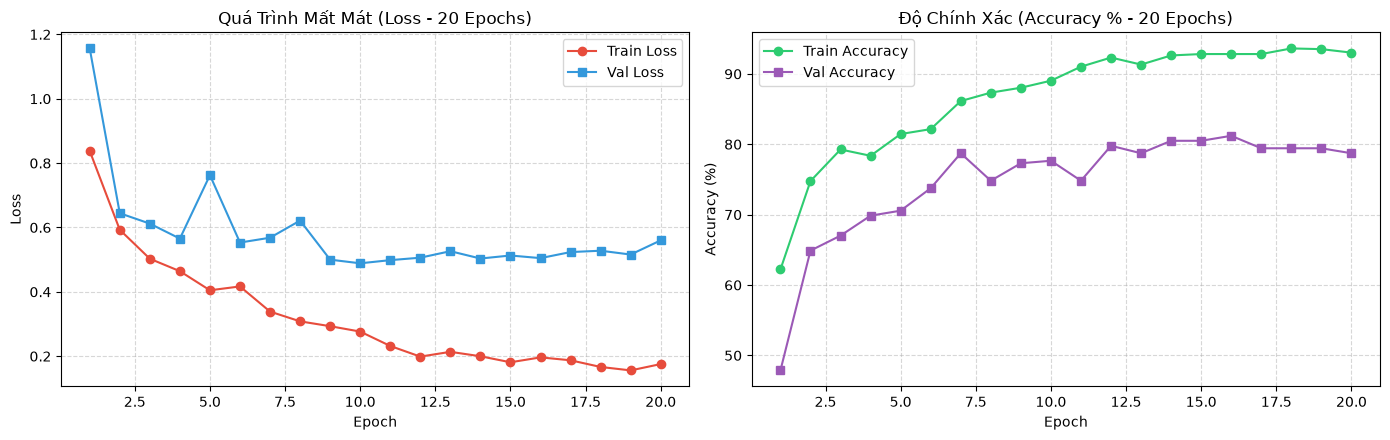

In [7]:
# Vẽ biểu đồ Loss & Accuracy qua 20 Epochs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))
ax1.plot(range(1, EPOCHS + 1), history["train_loss"], label="Train Loss", marker="o", color="#e74c3c")
ax1.plot(range(1, EPOCHS + 1), history["val_loss"], label="Val Loss", marker="s", color="#3498db")
ax1.set_title("Quá Trình Mất Mát (Loss - 20 Epochs)")
ax1.set_xlabel("Epoch")
ax1.set_ylabel("Loss")
ax1.grid(True, linestyle="--", alpha=0.5)
ax1.legend()

ax2.plot(range(1, EPOCHS + 1), history["train_acc"], label="Train Accuracy", marker="o", color="#2ecc71")
ax2.plot(range(1, EPOCHS + 1), history["val_acc"], label="Val Accuracy", marker="s", color="#9b59b6")
ax2.set_title("Độ Chính Xác (Accuracy % - 20 Epochs)")
ax2.set_xlabel("Epoch")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()

## 4. Pipeline Suy Luận & Tự Định Vị Lỗi Tự Động (Autonomous Defect Localization)
### Điểm đặc biệt của quy trình kiểm thử (Inference):
- **TUYỆT ĐỐI KHÔNG DÙNG FILE NHÃN (LABELS)** để khoanh vùng lỗi.
- Toàn bộ vị trí lỗi được **TỰ ĐỘNG ĐỊNH VỊ VÀ TỰ VẼ** dựa trên bản đồ nhiệt dị thường (Anomaly Heatmap) do ResNet-50 PatchCore trích xuất.
- Thuật toán `auto_localize_defect_box`:
  1. Phóng đại heatmap khớp tỷ lệ ảnh gốc $(W, H)$.
  2. Tìm vùng tập trung mật độ bất thường cao nhất $\ge 75\%$ cực đại.
  3. Tính tọa độ tâm $(c_x, c_y)$ và kích thước $(bw, bh)$.
  4. Tạo khung hình vuông quanh tâm bất thường kèm padding.
  5. Cắt khung hình vuông này và chuyển qua ResNet-18 phân loại xác suất 4 nhóm lỗi.

In [13]:
def inspect_sample(image_path, patchcore_detector, defect_classifier, device, show_plot=True):
    """
    Kiểm định mẫu sản phẩm qua Pipeline 2 giai đoạn (Không Crop / Không Định vị):
    - Stage 1: ResNet-50 PatchCore phân loại Lành vs Lỗi trên toàn ảnh.
    - Stage 2: ResNet-18 phân loại loại lỗi trực tiếp trên ảnh toàn phần.
    """
    image_path = Path(image_path)
    with Image.open(image_path) as raw_img:
        orig_img = raw_img.convert("RGB")

    # Preprocess chuẩn 224x224 chung cho cả 2 Stage
    preprocess = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
    ])
    tensor_img = preprocess(orig_img).unsqueeze(0).to(device)

    # GIAI ĐOẠN 1: PatchCore Anomaly Detection
    anomaly_score, heatmap = patchcore_detector.compute_anomaly(tensor_img)
    is_anomaly = anomaly_score > patchcore_detector.threshold

    result = {
        "image_name": image_path.name,
        "anomaly_score": anomaly_score,
        "threshold": patchcore_detector.threshold,
        "is_anomaly": is_anomaly,
        "status": "VẬT LỖI (ANOMALY)" if is_anomaly else "VẬT LÀNH (NORMAL)",
        "predicted_defect": None,
        "defect_probabilities": {}
    }

    # GIAI ĐOẠN 2: ResNet-18 Defect Classification (Đưa thẳng ảnh toàn phần)
    if is_anomaly:
        defect_classifier.eval()
        with torch.no_grad():
            logits = defect_classifier(tensor_img)
            probs = torch.softmax(logits, dim=1).squeeze().cpu().numpy()

        pred_idx = int(np.argmax(probs))
        result["predicted_defect"] = CLASS_NAMES[pred_idx]
        result["defect_probabilities"] = {
            name: float(prob * 100) for name, prob in zip(CLASS_NAMES, probs)
        }
    else:
        result["predicted_defect"] = "Không có lỗi (Normal)"
        result["defect_probabilities"] = {name: 0.0 for name in CLASS_NAMES}

    # BÁO CÁO KẾT QUẢ DẠNG VĂN BẢN
    print("=" * 70)
    print(f"🔍 BÁO CÁO KIỂM TRA MẪU: {image_path.name}")
    print(f"   • Điểm dị thường (Anomaly Score): {anomaly_score:.2f} (Ngưỡng tau: {patchcore_detector.threshold:.2f})")
    print(f"   • Phân loại Giai đoạn 1        : {'🔴 ' + result['status'] if is_anomaly else '🟢 ' + result['status']}")

    if is_anomaly:
        print(f"   • Kết luận loại lỗi Giai đoạn 2 : {result['predicted_defect'].upper()}")
        print("   • TỶ LỆ XÁC SUẤT CÁC LOẠI LỖI (RESNET-18):")
        for name, prob in result["defect_probabilities"].items():
            bar = "█" * int(round(prob / 5))
            print(f"     - {name:<10}: {prob:6.2f}% | {bar}")
    else:
        print("   • Đánh giá: Bề mặt đạt chuẩn chất lượng, an toàn cho băng tải.")
    print("=" * 70)

    # TRỰC QUAN HÓA (3 Khung hình gọn gàng)
    if show_plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

        # 1. Ảnh gốc
        axes[0].imshow(orig_img)
        axes[0].set_title(f"Ảnh Đầu Vào\n{image_path.name}", fontsize=11)
        axes[0].axis("off")

        # 2. PatchCore Heatmap (Chỉ vẽ Heatmap tổng quan)
        axes[1].imshow(orig_img)
        heatmap_plot = axes[1].imshow(heatmap, cmap="jet", alpha=0.55)
        color = "red" if is_anomaly else "green"
        axes[1].set_title(f"PatchCore Heatmap\nScore: {anomaly_score:.2f} ({result['status']})", color=color, fontweight="bold", fontsize=11)
        axes[1].axis("off")
        plt.colorbar(heatmap_plot, ax=axes[1], fraction=0.046, pad=0.04)

        # 3. Biểu đồ xác suất loại lỗi từ ResNet-18
        axes[2].clear()
        if is_anomaly:
            names = list(result["defect_probabilities"].keys())
            vals = list(result["defect_probabilities"].values())
            colors = ["#e74c3c" if n == result["predicted_defect"] else "#95a5a6" for n in names]
            bars = axes[2].barh(names, vals, color=colors)
            axes[2].set_xlim(0, 100)
            axes[2].set_xlabel("Tỷ lệ xác suất (%)")
            axes[2].set_title("Tỷ Lệ Các Loại Lỗi (ResNet-18)", fontsize=11, fontweight="bold")
            axes[2].grid(True, linestyle="--", alpha=0.5, axis="x")
            for bar, val in zip(bars, vals):
                axes[2].text(val + 1.5, bar.get_y() + bar.get_height() / 2, f"{val:.1f}%", va="center", fontsize=9, fontweight="bold")
        else:
            axes[2].text(0.5, 0.5, "✅ VẬT LÀNH (NORMAL)\nKhông kích hoạt ResNet-18", ha="center", va="center", fontsize=12, color="green", fontweight="bold")
            axes[2].set_axis_off()

        plt.tight_layout()
        plt.show()

    return result

## 5. Kiểm Thử Toàn Diện: Đánh Giá Đồng Thời Mẫu Lành và Mẫu Lỗi
Quy trình kiểm thử:
1. Lấy ngẫu nhiên các mẫu **Vật Không Lỗi (Normal - nhãn 1)** từ tập kiểm định.
2. Lấy ngẫu nhiên các mẫu **Vật Có Lỗi (Defects - nhãn 2-5)** từ tập test.
3. Chạy qua toàn bộ pipeline: ResNet-50 phân định Lành/Lỗi $\rightarrow$ Tự định vị vết lỗi $\rightarrow$ ResNet-18 phân loại xác suất.

🧪 TIẾN HÀNH KIỂM THỬ ĐỒNG THỜI CẢ MẪU LÀNH VÀ MẪU LỖI (TỰ ĐỊNH VỊ KHÔNG DÙNG LABELS)

🟢 [PHẦN 1] KIỂM THỬ 2 ẢNH VẬT LÀNH (NORMAL) ĐỂ KIỂM CHỨNG RESNET-50:

--- [Mẫu Lành #1/2: p7f_2_C_png.rf.67a1e3cc7f6ee415cbb051224a1499c0.jpg] ---
🔍 BÁO CÁO KIỂM TRA MẪU: p7f_2_C_png.rf.67a1e3cc7f6ee415cbb051224a1499c0.jpg
   • Điểm dị thường (Anomaly Score): 11.00 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🟢 VẬT LÀNH (NORMAL)
   • Đánh giá: Bề mặt đạt chuẩn chất lượng, an toàn cho băng tải.


C:\Users\Admin\AppData\Local\Temp\ipykernel_18724\3625156240.py:99: UserWarning: Glyph 9989 (\N{WHITE HEAVY CHECK MARK}) missing from font(s) DejaVu Sans.
  plt.tight_layout()


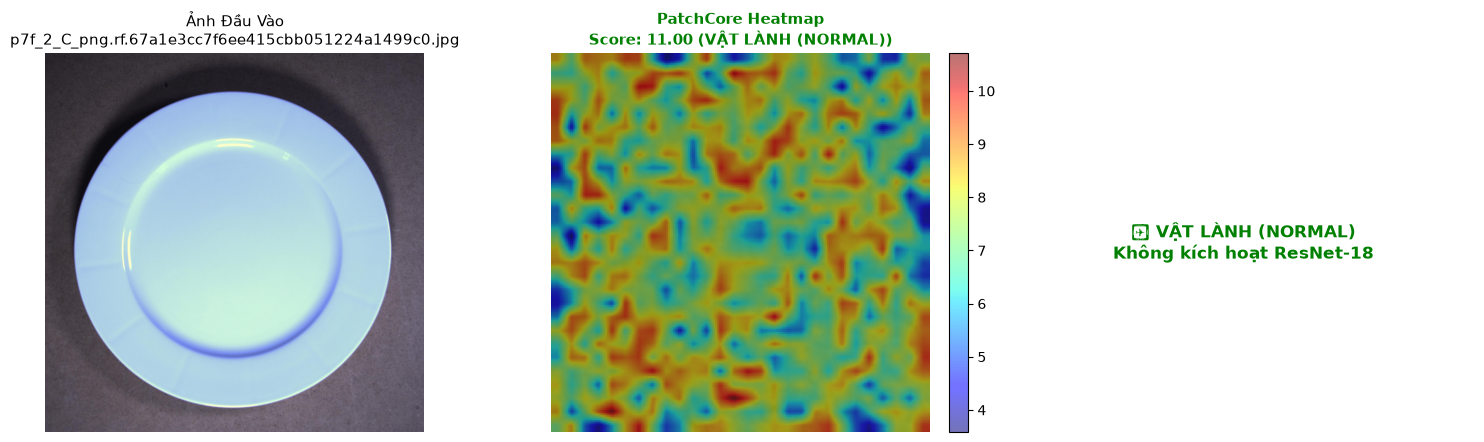


--- [Mẫu Lành #2/2: p24v_4_C_png.rf.26ec93f4f2f1475cd847404e75b3d9a5.jpg] ---
🔍 BÁO CÁO KIỂM TRA MẪU: p24v_4_C_png.rf.26ec93f4f2f1475cd847404e75b3d9a5.jpg
   • Điểm dị thường (Anomaly Score): 11.99 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🟢 VẬT LÀNH (NORMAL)
   • Đánh giá: Bề mặt đạt chuẩn chất lượng, an toàn cho băng tải.


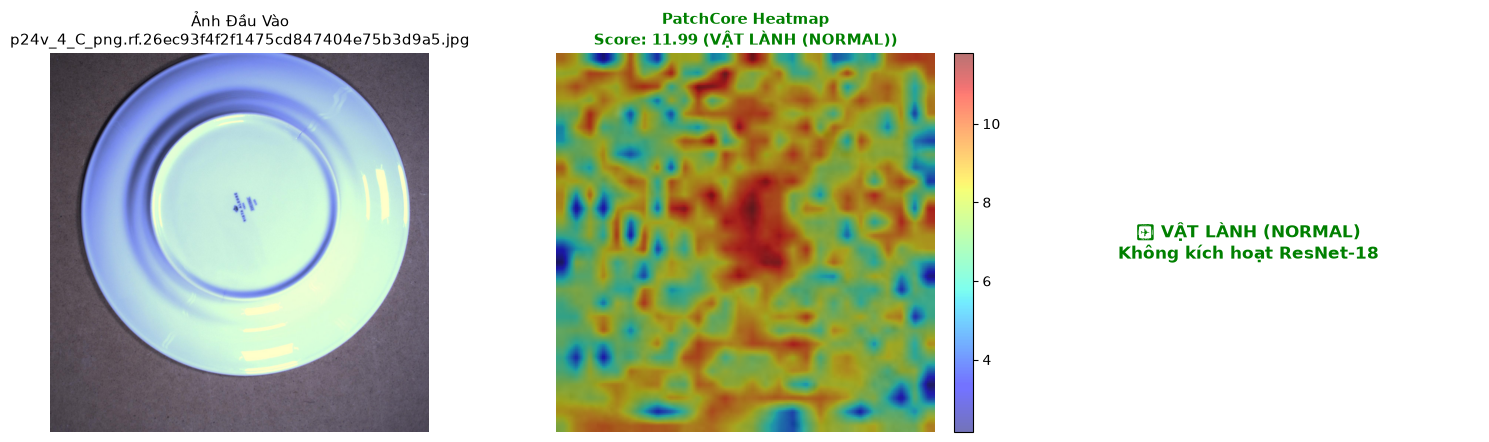


🔴 [PHẦN 2] KIỂM THỬ 3 ẢNH TỪ TẬP TEST ĐỂ KIỂM CHỨNG PHÂN LOẠI LỖI RESNET-18:

--- [Mẫu Test #1/3: 106_jpg.rf.3ce69408f39f150a870d52568b2b2566.jpg] ---
🔍 BÁO CÁO KIỂM TRA MẪU: 106_jpg.rf.3ce69408f39f150a870d52568b2b2566.jpg
   • Điểm dị thường (Anomaly Score): 28.18 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🔴 VẬT LỖI (ANOMALY)
   • Kết luận loại lỗi Giai đoạn 2 : PIN_HOLE
   • TỶ LỆ XÁC SUẤT CÁC LOẠI LỖI (RESNET-18):
     - crack     :  12.11% | ██
     - glaze     :  27.38% | █████
     - pin_hole  :  59.50% | ████████████
     - scratch   :   1.01% | 


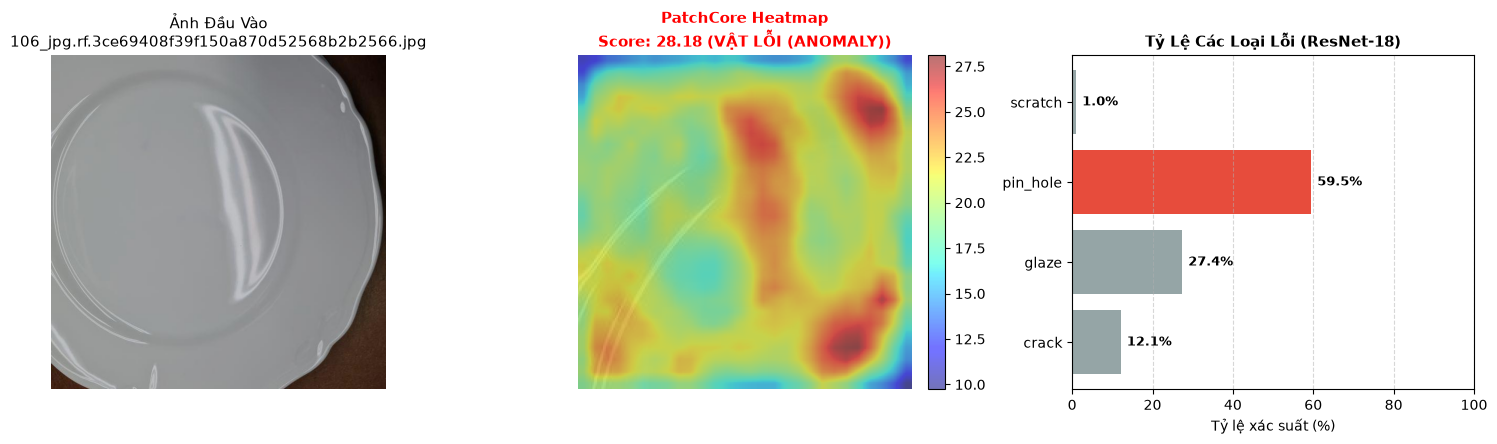


--- [Mẫu Test #2/3: 198_jpg.rf.92c26eab2fef27128de22942eaa731e1.jpg] ---
🔍 BÁO CÁO KIỂM TRA MẪU: 198_jpg.rf.92c26eab2fef27128de22942eaa731e1.jpg
   • Điểm dị thường (Anomaly Score): 23.92 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🔴 VẬT LỖI (ANOMALY)
   • Kết luận loại lỗi Giai đoạn 2 : PIN_HOLE
   • TỶ LỆ XÁC SUẤT CÁC LOẠI LỖI (RESNET-18):
     - crack     :   1.50% | 
     - glaze     :  16.59% | ███
     - pin_hole  :  81.75% | ████████████████
     - scratch   :   0.16% | 


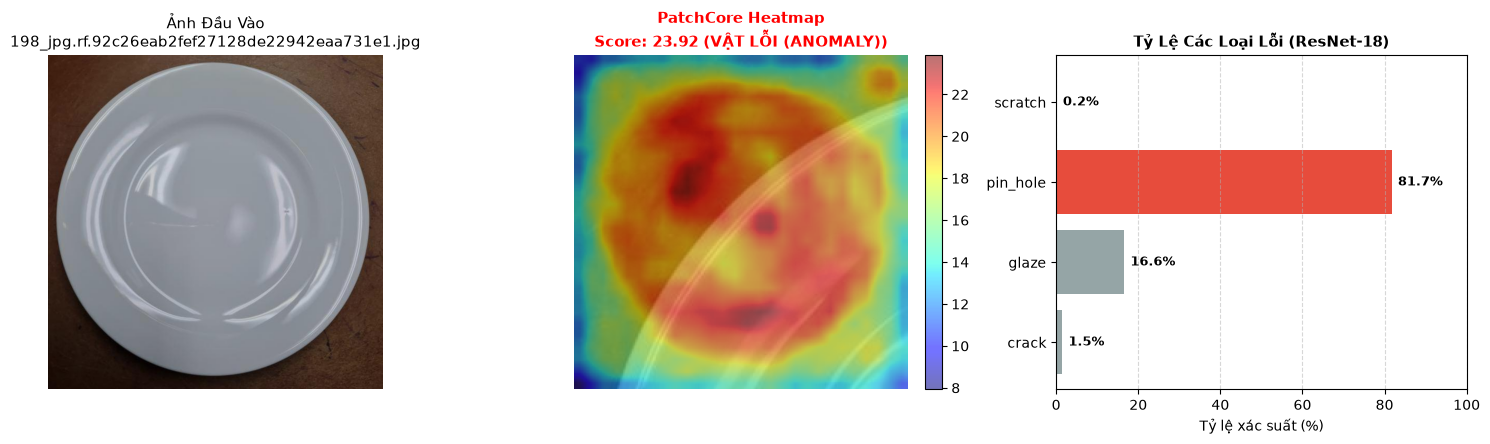


--- [Mẫu Test #3/3: 282_jpg.rf.5442d66f5ab6624fe883db63e5162d09.jpg] ---
🔍 BÁO CÁO KIỂM TRA MẪU: 282_jpg.rf.5442d66f5ab6624fe883db63e5162d09.jpg
   • Điểm dị thường (Anomaly Score): 26.78 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🔴 VẬT LỖI (ANOMALY)
   • Kết luận loại lỗi Giai đoạn 2 : GLAZE
   • TỶ LỆ XÁC SUẤT CÁC LOẠI LỖI (RESNET-18):
     - crack     :   1.72% | 
     - glaze     :  77.08% | ███████████████
     - pin_hole  :  20.94% | ████
     - scratch   :   0.26% | 


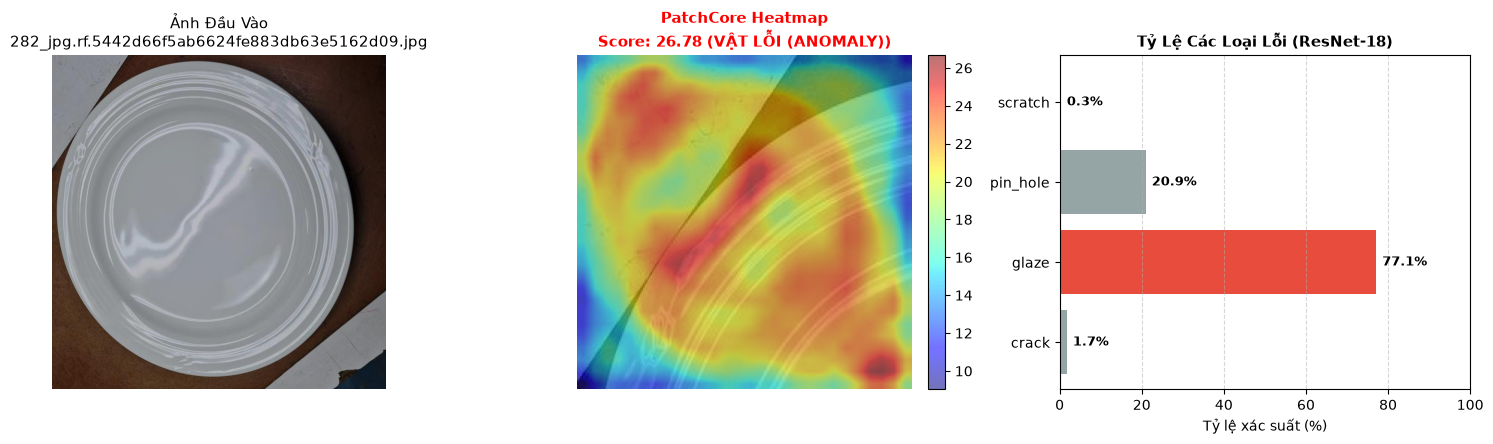

In [14]:
def run_comprehensive_evaluation(num_normals=2, num_defects=3):
    """
    Kiểm thử đồng thời cả ảnh Không Lỗi (Normal) và ảnh Có Lỗi (Defect)
    để xác nhận tính đúng đắn của cả 2 mô hình ResNet-50 và ResNet-18.
    """
    print("=" * 82)
    print("🧪 TIẾN HÀNH KIỂM THỬ ĐỒNG THỜI CẢ MẪU LÀNH VÀ MẪU LỖI (TỰ ĐỊNH VỊ KHÔNG DÙNG LABELS)")
    print("=" * 82)

    # 1. KIỂM THỬ TRÊN MẪU VẬT LÀNH (NORMAL - NHÃN 1)
    normal_candidates = val_normal if len(val_normal) > 0 else train_normal
    selected_normals = random.sample(normal_candidates, min(num_normals, len(normal_candidates)))

    print(f"\n🟢 [PHẦN 1] KIỂM THỬ {len(selected_normals)} ẢNH VẬT LÀNH (NORMAL) ĐỂ KIỂM CHỨNG RESNET-50:")
    for idx, p in enumerate(selected_normals, 1):
        print(f"\n--- [Mẫu Lành #{idx}/{len(selected_normals)}: {p.name}] ---")
        inspect_sample(
            image_path=p,
            patchcore_detector=detector,
            defect_classifier=model_r18,
            device=device,
            show_plot=True
        )

    # 2. KIỂM THỬ TRÊN MẪU VẬT LỖI (DEFECTS) TỪ TẬP TEST
    defect_candidates = test_all
    selected_defects = random.sample(defect_candidates, min(num_defects, len(defect_candidates)))

    print(f"\n🔴 [PHẦN 2] KIỂM THỬ {len(selected_defects)} ẢNH TỪ TẬP TEST ĐỂ KIỂM CHỨNG PHÂN LOẠI LỖI RESNET-18:")
    for idx, p in enumerate(selected_defects, 1):
        print(f"\n--- [Mẫu Test #{idx}/{len(selected_defects)}: {p.name}] ---")
        inspect_sample(
            image_path=p,
            patchcore_detector=detector,
            defect_classifier=model_r18,
            device=device,
            show_plot=True
        )

# Chạy kiểm thử toàn diện cả mẫu lành và mẫu lỗi
run_comprehensive_evaluation(num_normals=2, num_defects=3)


🎯 KIỂM THỬ NHANH 1 ẢNH NGẪU NHIÊN TẬP TEST:
🔍 BÁO CÁO KIỂM TRA MẪU: 283_jpg.rf.d5b2d6fc4fa4cadb971bfba66c365253.jpg
   • Điểm dị thường (Anomaly Score): 26.95 (Ngưỡng tau: 19.26)
   • Phân loại Giai đoạn 1        : 🔴 VẬT LỖI (ANOMALY)
   • Tọa độ tự định vị (Heatmap)  : (8, 8, 640, 640)
   • Kết luận loại lỗi Giai đoạn 2 : GLAZE
   • TỶ LỆ XÁC SUẤT CÁC LOẠI LỖI (RESNET-18):
     - crack     :   0.19% | 
     - glaze     :  88.81% | ██████████████████
     - pin_hole  :  10.87% | ██
     - scratch   :   0.12% | 


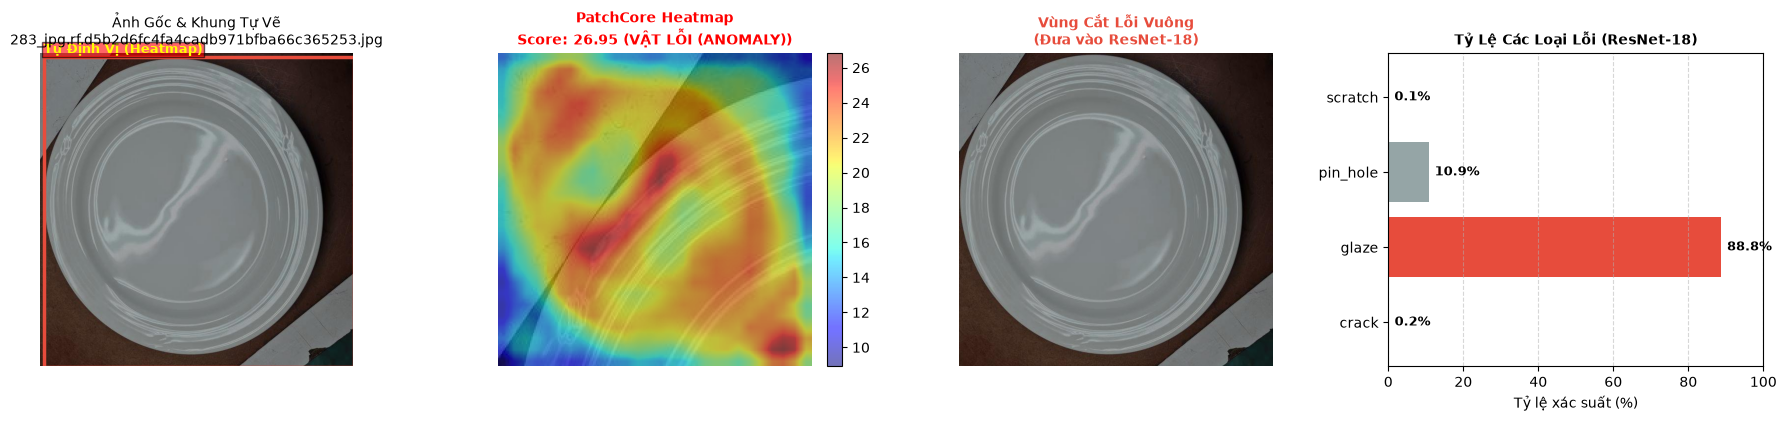

In [10]:
# Kiểm thử nhanh một ảnh ngẫu nhiên bất kỳ từ tập TEST
print("\n🎯 KIỂM THỬ NHANH 1 ẢNH NGẪU NHIÊN TẬP TEST:")
if test_all:
    random_test_img = random.choice(test_all)
    inspect_sample(
        image_path=random_test_img,
        patchcore_detector=detector,
        defect_classifier=model_r18,
        device=device,
        show_plot=True
    )

⏳ Đang chạy đánh giá PatchCore trên tập Test (11 ảnh lành, 78 ảnh lỗi)...

📊 BÁO CÁO ĐÁNH GIÁ ĐỘ CHÍNH XÁC CỦA RESNET-50 PATCHCORE (STAGE 1)
 • Tỷ lệ dự đoán đúng (Accuracy) : 100.00%
 • Ngưỡng Tau đang áp dụng (Threshold): 19.26
 • Chỉ số phân biệt lỗi (AUROC)    : 100.00%

Chi tiết báo cáo:
                   precision    recall  f1-score   support

Vật Lành (Normal)       1.00      1.00      1.00        11
 Vật Lỗi (Defect)       1.00      1.00      1.00        78

         accuracy                           1.00        89
        macro avg       1.00      1.00      1.00        89
     weighted avg       1.00      1.00      1.00        89



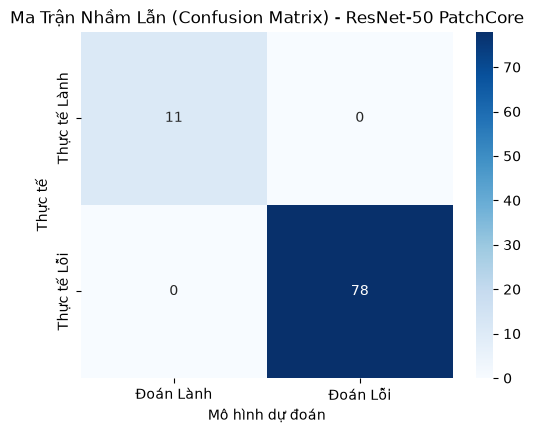

In [19]:
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import seaborn as sns

def evaluate_patchcore_on_testset(patchcore_detector, test_normal_paths, test_defect_paths, transform):
    """
    Đánh giá tỷ lệ dự đoán đúng/sai toàn diện của ResNet-50 PatchCore trên tập Test
    """
    y_true = []   # 0: Normal (Lành), 1: Defect (Lỗi)
    y_scores = [] # Anomaly Score từ PatchCore
    y_pred = []   # Dự đoán dựa trên ngưỡng tau (0 hoặc 1)
    
    print(f"⏳ Đang chạy đánh giá PatchCore trên tập Test ({len(test_normal_paths)} ảnh lành, {len(test_defect_paths)} ảnh lỗi)...")
    
    # 1. Quét qua toàn bộ ảnh Lành (Label 0)
    for p in test_normal_paths:
        with Image.open(p) as img:
            t = transform(img.convert("RGB")).unsqueeze(0).to(device)
        score, _ = patchcore_detector.compute_anomaly(t)
        y_true.append(0)
        y_scores.append(score)
        y_pred.append(1 if score > patchcore_detector.threshold else 0)
        
    # 2. Quét qua toàn bộ ảnh Lỗi (Label 1)
    for p in test_defect_paths:
        with Image.open(p) as img:
            t = transform(img.convert("RGB")).unsqueeze(0).to(device)
        score, _ = patchcore_detector.compute_anomaly(t)
        y_true.append(1)
        y_scores.append(score)
        y_pred.append(1 if score > patchcore_detector.threshold else 0)
        
    if not y_true:
        print("❌ Không tìm thấy ảnh trong tập Test để đánh giá!")
        return

    # 3. Tính toán các chỉ số thống kê
    acc = accuracy_score(y_true, y_pred) * 100
    
    # Kiểm tra xem có đủ cả 2 nhãn (0 và 1) để tính AUROC và classification_report hay không
    unique_classes = set(y_true)
    
    print("\n" + "="*60)
    print("📊 BÁO CÁO ĐÁNH GIÁ ĐỘ CHÍNH XÁC CỦA RESNET-50 PATCHCORE (STAGE 1)")
    print("="*60)
    print(f" • Tỷ lệ dự đoán đúng (Accuracy) : {acc:.2f}%")
    print(f" • Ngưỡng Tau đang áp dụng (Threshold): {patchcore_detector.threshold:.2f}")

    if len(unique_classes) > 1:
        auroc = roc_auc_score(y_true, y_scores) * 100
        print(f" • Chỉ số phân biệt lỗi (AUROC)    : {auroc:.2f}%")
        print("\nChi tiết báo cáo:")
        print(classification_report(y_true, y_pred, target_names=["Vật Lành (Normal)", "Vật Lỗi (Defect)"], zero_division=0))
        
        # Trực quan hóa Confusion Matrix
        cm = confusion_matrix(y_true, y_pred)
        plt.figure(figsize=(6, 4.5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
                    xticklabels=["Đoán Lành", "Đoán Lỗi"], 
                    yticklabels=["Thực tế Lành", "Thực tế Lỗi"])
        plt.title("Ma Trận Nhầm Lẫn (Confusion Matrix) - ResNet-50 PatchCore")
        plt.ylabel("Thực tế")
        plt.xlabel("Mô hình dự đoán")
        plt.show()
    else:
        print("\n⚠️ Tập Test hiện tại chỉ có 1 loại nhãn dữ liệu (chỉ có Lành hoặc chỉ có Lỗi).")
        print(classification_report(y_true, y_pred, zero_division=0))

# 🚀 Chạy lại đánh giá trên tập Test
test_defect_paths = list(set([item["img_path"] for item in test_defect_crops]))
# Nếu test_normal rỗng, tự động bổ sung ảnh val_normal vào để đánh giá đủ 2 nhãn
eval_normal_paths = test_normal if len(test_normal) > 0 else val_normal

evaluate_patchcore_on_testset(detector, eval_normal_paths, test_defect_paths, patchcore_transform)